In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download("mostafaabla/garbage-classification")

print("Dataset downloaded successfully!")
print("Dataset path:", dataset_path)

Using Colab cache for faster access to the 'garbage-classification' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/garbage-classification


In [ ]:
import os

print("Main folders:")
print(os.listdir(dataset_path))

Main folders:
['garbage_classification']


In [ ]:
for folder, subfolders, files in os.walk(dataset_path):
    if files:
        print(os.path.basename(folder), ":", len(files), "files")

metal : 769 files
white-glass : 775 files
biological : 985 files
paper : 1050 files
brown-glass : 607 files
battery : 945 files
trash : 697 files
cardboard : 891 files
shoes : 1977 files
clothes : 5325 files
plastic : 865 files
green-glass : 629 files


In [ ]:
import os

dataset_dir = os.path.join(dataset_path, "garbage_classification")

classes = sorted(os.listdir(dataset_dir))

total_images = 0

print("Dataset Classes and Image Counts:\n")

for class_name in classes:
    class_path = os.path.join(dataset_dir, class_name)

    if os.path.isdir(class_path):
        images = [
            file for file in os.listdir(class_path)
            if file.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        count = len(images)
        total_images += count

        print(class_name, ":", count)

print("\nTotal Classes:", len(classes))
print("Total Images:", total_images)

Dataset Classes and Image Counts:

battery : 945
biological : 985
brown-glass : 607
cardboard : 891
clothes : 5325
green-glass : 629
metal : 769
paper : 1050
plastic : 865
shoes : 1977
trash : 697
white-glass : 775

Total Classes: 12
Total Images: 15515


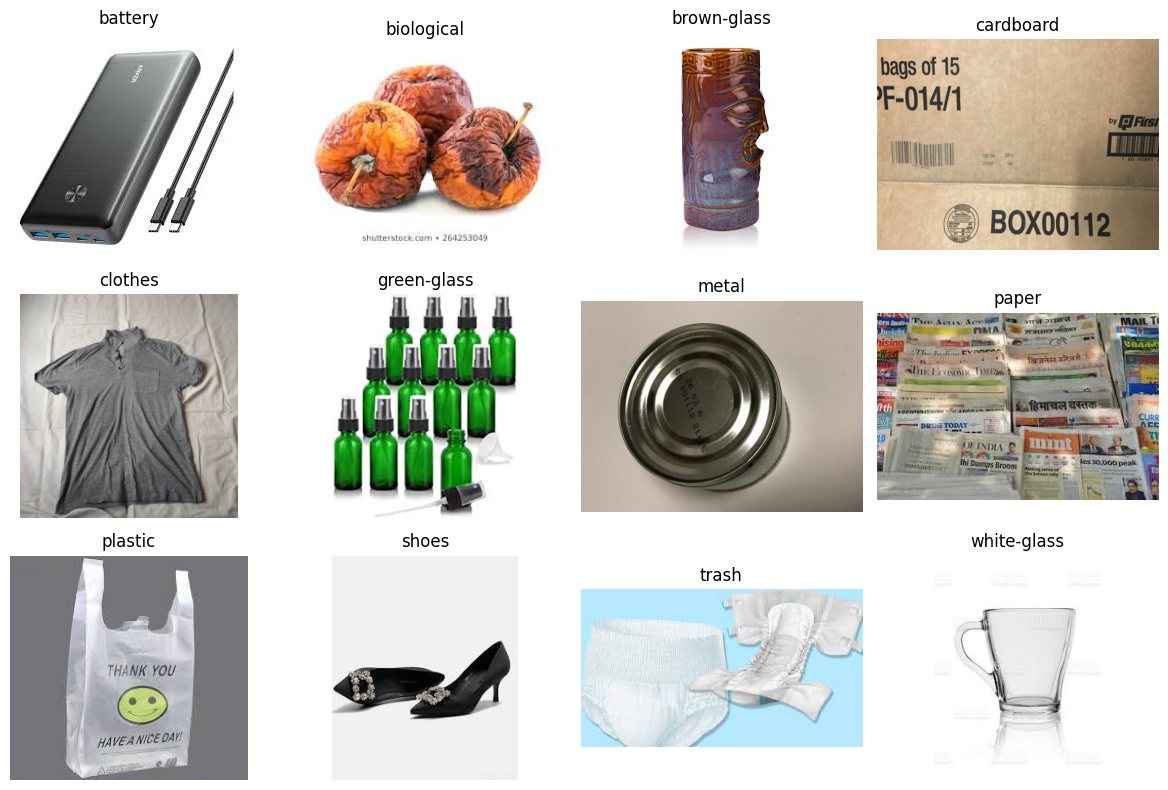

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes[:12]):
    class_path = os.path.join(dataset_dir, class_name)

    image_name = random.choice(os.listdir(class_path))
    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

# Image preprocessing
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# Load dataset
full_dataset = datasets.ImageFolder(dataset_dir)

# Get image paths and labels
indices = list(range(len(full_dataset)))
labels = full_dataset.targets

# Split into training and temporary data
train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Split temporary data into validation and testing
val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    stratify=[labels[i] for i in temp_indices],
    random_state=42
)

# Create datasets
train_dataset = datasets.ImageFolder(
    dataset_dir, transform=train_transform
)

test_dataset = datasets.ImageFolder(
    dataset_dir, transform=test_transform
)

train_data = Subset(train_dataset, train_indices)
val_data = Subset(test_dataset, val_indices)
test_data = Subset(test_dataset, test_indices)

print("Training Images:", len(train_data))
print("Validation Images:", len(val_data))
print("Testing Images:", len(test_data))
print("Total Images:", len(train_data) + len(val_data) + len(test_data))
print("Classes:", full_dataset.classes)

Training Images: 10860
Validation Images: 2327
Testing Images: 2328
Total Images: 15515
Classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


In [ ]:
batch_size = 32

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders Created Successfully!")
print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

DataLoaders Created Successfully!
Training Batches: 340
Validation Batches: 73
Testing Batches: 73


In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
num_classes = len(full_dataset.classes)

def create_model(model_name):

    if model_name == "ResNet18":
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "MobileNetV2":
        model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features, num_classes
        )

    elif model_name == "EfficientNetB0":
        model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features, num_classes
        )

    return model.to(device)


print("Three models are ready for implementation:")
print("1. ResNet18")
print("2. MobileNetV2")
print("3. EfficientNet-B0")

Three models are ready for implementation:
1. ResNet18
2. MobileNetV2
3. EfficientNet-B0


In [ ]:
model_names = ["ResNet18", "MobileNetV2", "EfficientNetB0"]

for name in model_names:

    model = create_model(name)

    total_params = sum(p.numel() for p in model.parameters())

    print("\nModel:", name)
    print("Total Parameters:", total_params)
    print("Output Classes:", num_classes)

    del model

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 175MB/s]



Model: ResNet18
Total Parameters: 11182668
Output Classes: 12
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 119MB/s]



Model: MobileNetV2
Total Parameters: 2239244
Output Classes: 12
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 143MB/s]



Model: EfficientNetB0
Total Parameters: 4022920
Output Classes: 12


In [ ]:
import copy
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm

criterion = nn.CrossEntropyLoss()

def train_model(model, model_name, epochs=5):

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.0001,
        weight_decay=0.0001
    )

    best_accuracy = 0.0

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    start_time = time.time()

    for epoch in range(epochs):

        model.train()
        train_loss = 0
        train_correct = 0
        train_total = 0

        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()

        train_loss /= train_total
        train_accuracy = 100 * train_correct / train_total

        model.eval()
        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss /= val_total
        val_accuracy = 100 * val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        print(f"\nEpoch {epoch+1}/{epochs}")
        print(f"Training Loss: {train_loss:.4f}")
        print(f"Training Accuracy: {train_accuracy:.2f}%")
        print(f"Validation Loss: {val_loss:.4f}")
        print(f"Validation Accuracy: {val_accuracy:.2f}%")

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            torch.save(model.state_dict(), f"{model_name}_best.pth")

    training_time = time.time() - start_time

    print(f"\n{model_name} Training Completed!")
    print(f"Best Validation Accuracy: {best_accuracy:.2f}%")
    print(f"Training Time: {training_time/60:.2f} minutes")

    return history, best_accuracy, training_time

In [ ]:
model_names = ["ResNet18", "MobileNetV2", "EfficientNetB0"]

results = {}

for name in model_names:

    print("\nTraining:", name)

    model = create_model(name)

    history, accuracy, training_time = train_model(
        model, name, epochs=5
    )

    results[name] = {
        "history": history,
        "accuracy": accuracy,
        "training_time": training_time
    }

    del model
    torch.cuda.empty_cache()

print("\nAll Models Training Completed!")


Training: ResNet18


Epoch 1/5: 100%|██████████| 340/340 [01:06<00:00,  5.08it/s]



Epoch 1/5
Training Loss: 0.3557
Training Accuracy: 89.44%
Validation Loss: 0.1719
Validation Accuracy: 95.06%


Epoch 2/5: 100%|██████████| 340/340 [00:49<00:00,  6.87it/s]



Epoch 2/5
Training Loss: 0.1197
Training Accuracy: 96.43%
Validation Loss: 0.1327
Validation Accuracy: 95.75%


Epoch 3/5: 100%|██████████| 340/340 [00:50<00:00,  6.71it/s]


... (21 outputs left out)

Epoch 4/5: 100%|██████████| 340/340 [00:57<00:00,  5.94it/s]



Epoch 4/5
Training Loss: 0.0611
Training Accuracy: 98.26%
Validation Loss: 0.0893
Validation Accuracy: 97.38%


Epoch 5/5: 100%|██████████| 340/340 [00:57<00:00,  5.91it/s]



Epoch 5/5
Training Loss: 0.0427
Training Accuracy: 98.90%
Validation Loss: 0.0935
Validation Accuracy: 97.38%

EfficientNetB0 Training Completed!
Best Validation Accuracy: 97.38%
Training Time: 5.63 minutes

All Models Training Completed!


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import numpy as np

test_results = {}
predictions = {}
probabilities = {}
actual_labels = {}

for name in model_names:

    print("\nEvaluating:", name)

    model = create_model(name)
    model.load_state_dict(
        torch.load(f"{name}_best.pth", map_location=device)
    )
    model.eval()

    y_true = []
    y_pred = []
    y_prob = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)

            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)

            predicted = torch.argmax(outputs, dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predicted.cpu().numpy())
            y_prob.extend(probs.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    test_results[name] = {
        "Accuracy": accuracy * 100,
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1 Score": f1 * 100
    }

    predictions[name] = np.array(y_pred)
    probabilities[name] = np.array(y_prob)
    actual_labels[name] = np.array(y_true)

    print(f"Test Accuracy: {accuracy*100:.2f}%")
    print(f"Precision: {precision*100:.2f}%")
    print(f"Recall: {recall*100:.2f}%")
    print(f"F1 Score: {f1*100:.2f}%")

    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred,
        labels=list(range(num_classes)),
        target_names=full_dataset.classes,
        zero_division=0
    ))

    del model
    torch.cuda.empty_cache()


Evaluating: ResNet18
Test Accuracy: 95.53%
Precision: 95.63%
Recall: 95.53%
F1 Score: 95.54%

Classification Report:
              precision    recall  f1-score   support

     battery       0.99      0.93      0.96       142
  biological       0.91      0.99      0.94       148
 brown-glass       0.99      0.90      0.94        91
   cardboard       0.95      0.94      0.94       134
     clothes       0.99      0.98      0.99       799
 green-glass       0.96      0.97      0.96        94
       metal       0.95      0.92      0.93       115
       paper       0.95      0.94      0.95       158
     plastic       0.85      0.89      0.87       130
       shoes       0.94      0.97      0.95       297
       trash       0.93      0.96      0.94       104
 white-glass       0.94      0.91      0.92       116

    accuracy                           0.96      2328
   macro avg       0.94      0.94      0.94      2328
weighted avg       0.96      0.96      0.96      2328


Evaluating: Mo

In [ ]:
import pandas as pd

comparison_df = pd.DataFrame(test_results).T

print("Model Performance Comparison")
display(comparison_df.round(2))

best_model = comparison_df["Accuracy"].idxmax()

print("\nBest Model:", best_model)
print("Test Accuracy:", round(comparison_df.loc[best_model, "Accuracy"], 2), "%")

Model Performance Comparison


,Accuracy,Precision,Recall,F1 Score
ResNet18,95.53,95.63,95.53,95.54
MobileNetV2,97.12,97.17,97.12,97.12
EfficientNetB0,96.91,96.96,96.91,96.91



Best Model: MobileNetV2
Test Accuracy: 97.12 %


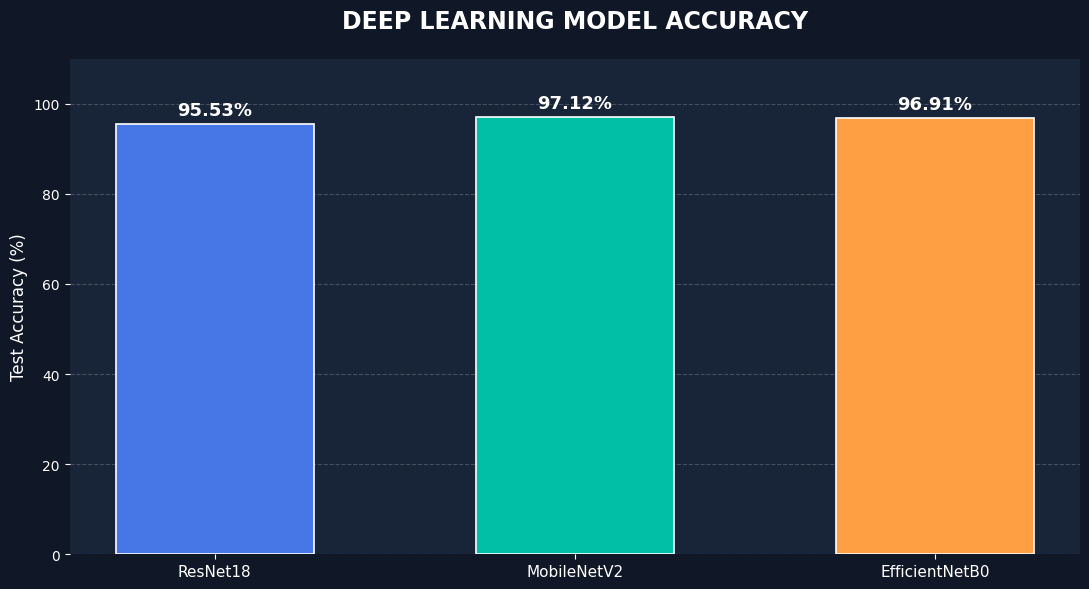

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = comparison_df.index.tolist()
accuracies = comparison_df["Accuracy"].values

colors = ["#4776E6", "#00BFA6", "#FF9F43"]

fig, ax = plt.subplots(figsize=(11, 6))

fig.patch.set_facecolor("#101827")
ax.set_facecolor("#182438")

bars = ax.bar(
    models,
    accuracies,
    color=colors,
    width=0.55,
    edgecolor="white",
    linewidth=1.2,
    zorder=3
)

for bar, value in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        color="white",
        fontsize=13,
        fontweight="bold"
    )

ax.set_title(
    "DEEP LEARNING MODEL ACCURACY",
    fontsize=17,
    fontweight="bold",
    color="white",
    pad=22
)

ax.set_ylabel("Test Accuracy (%)", color="white", fontsize=12)

ax.set_ylim(0, 110)

ax.tick_params(axis="x", colors="white", labelsize=11)
ax.tick_params(axis="y", colors="white", labelsize=10)

ax.grid(axis="y", linestyle="--", alpha=0.2, color="white", zorder=0)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

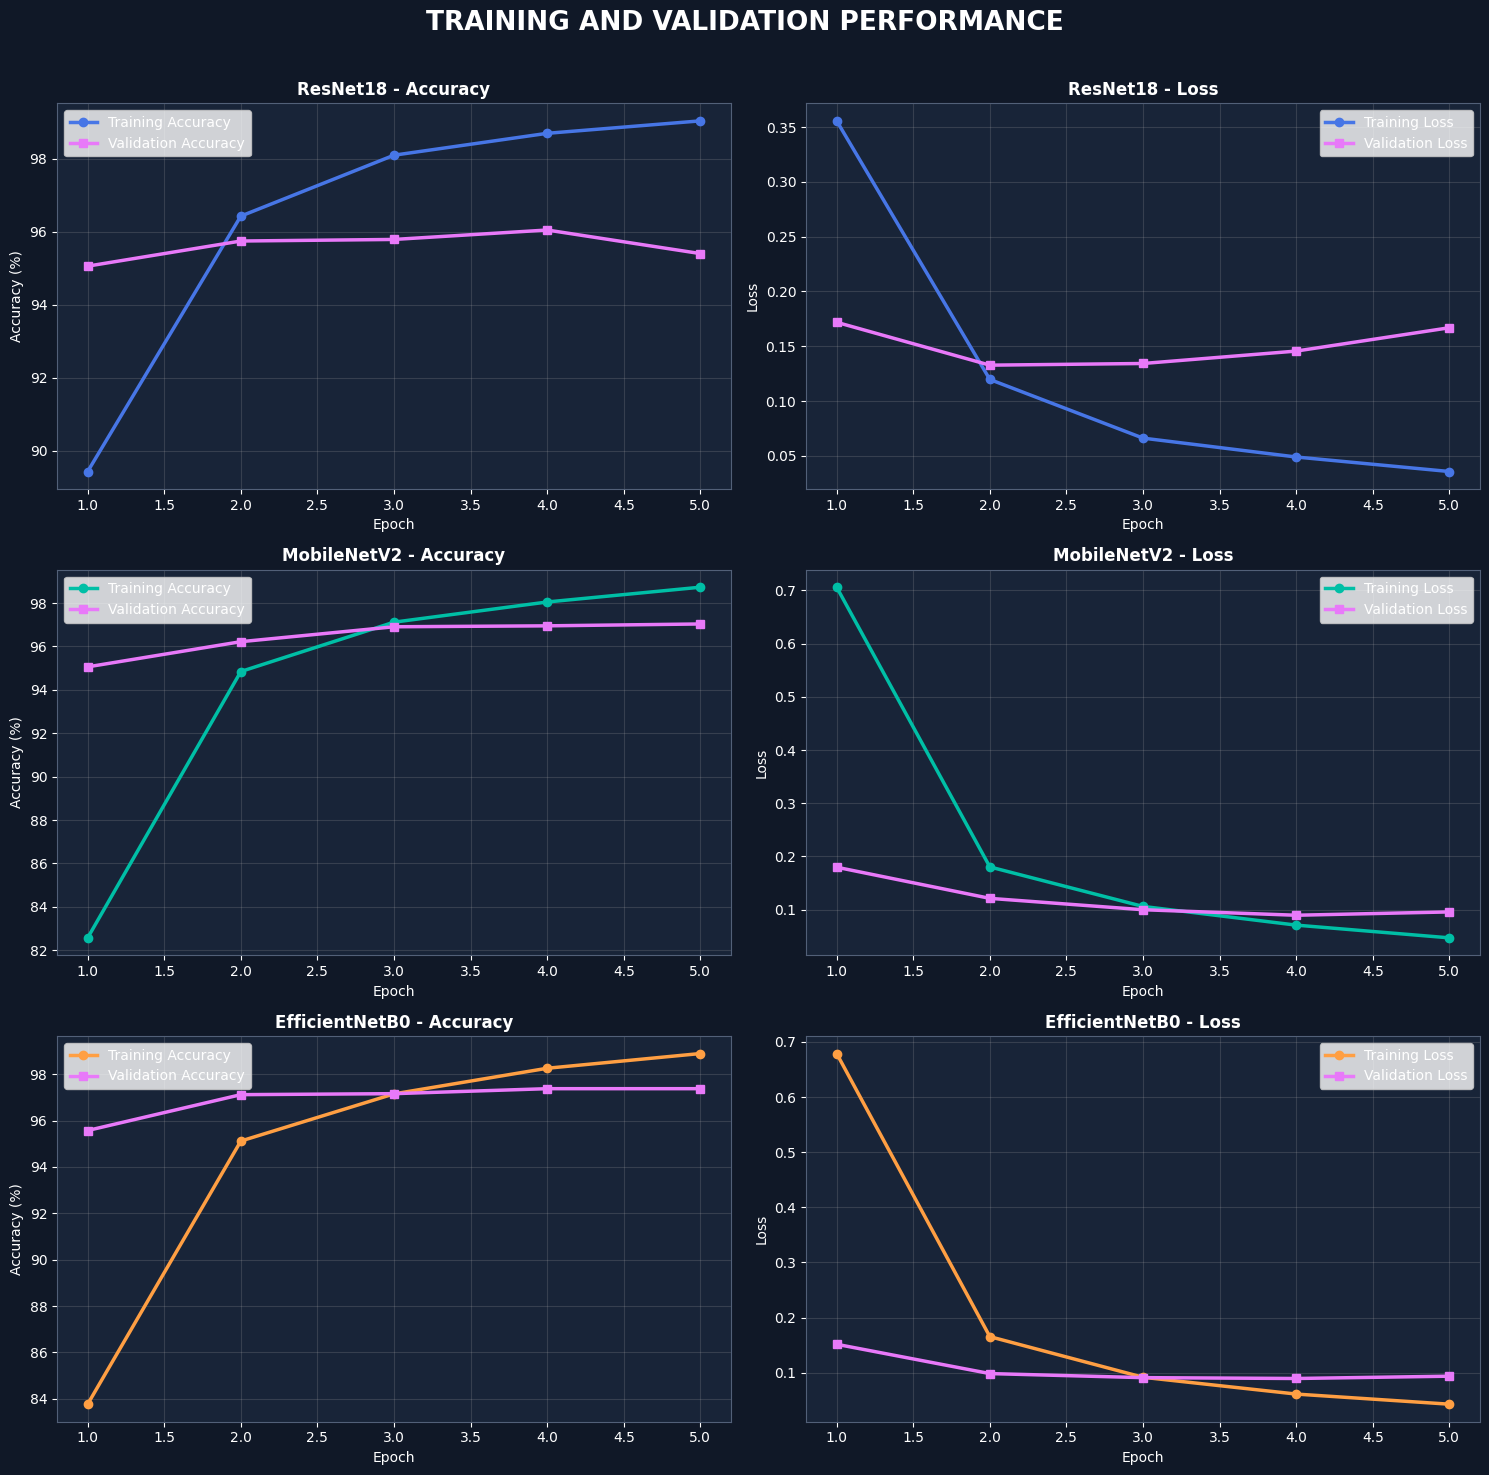

In [ ]:
import matplotlib.pyplot as plt

model_names = ["ResNet18", "MobileNetV2", "EfficientNetB0"]

colors = {
    "ResNet18": "#4776E6",
    "MobileNetV2": "#00BFA6",
    "EfficientNetB0": "#FF9F43"
}

fig, axes = plt.subplots(3, 2, figsize=(15, 15))

fig.patch.set_facecolor("#101827")

for i, name in enumerate(model_names):

    history = results[name]["history"]
    epochs = range(1, len(history["train_accuracy"]) + 1)

    # Accuracy graph
    ax1 = axes[i, 0]
    ax1.set_facecolor("#182438")

    ax1.plot(
        epochs, history["train_accuracy"],
        marker="o", linewidth=2.5,
        color=colors[name], label="Training Accuracy"
    )

    ax1.plot(
        epochs, history["val_accuracy"],
        marker="s", linewidth=2.5,
        color="#E879F9", label="Validation Accuracy"
    )

    ax1.set_title(f"{name} - Accuracy", color="white", fontweight="bold")
    ax1.set_xlabel("Epoch", color="white")
    ax1.set_ylabel("Accuracy (%)", color="white")
    ax1.legend()
    ax1.grid(alpha=0.2)

    # Loss graph
    ax2 = axes[i, 1]
    ax2.set_facecolor("#182438")

    ax2.plot(
        epochs, history["train_loss"],
        marker="o", linewidth=2.5,
        color=colors[name], label="Training Loss"
    )

    ax2.plot(
        epochs, history["val_loss"],
        marker="s", linewidth=2.5,
        color="#E879F9", label="Validation Loss"
    )

    ax2.set_title(f"{name} - Loss", color="white", fontweight="bold")
    ax2.set_xlabel("Epoch", color="white")
    ax2.set_ylabel("Loss", color="white")
    ax2.legend()
    ax2.grid(alpha=0.2)

    for ax in [ax1, ax2]:
        ax.tick_params(colors="white")
        for spine in ax.spines.values():
            spine.set_color("#526078")

        legend = ax.get_legend()
        for text in legend.get_texts():
            text.set_color("white")

fig.suptitle(
    "TRAINING AND VALIDATION PERFORMANCE",
    fontsize=19,
    color="white",
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

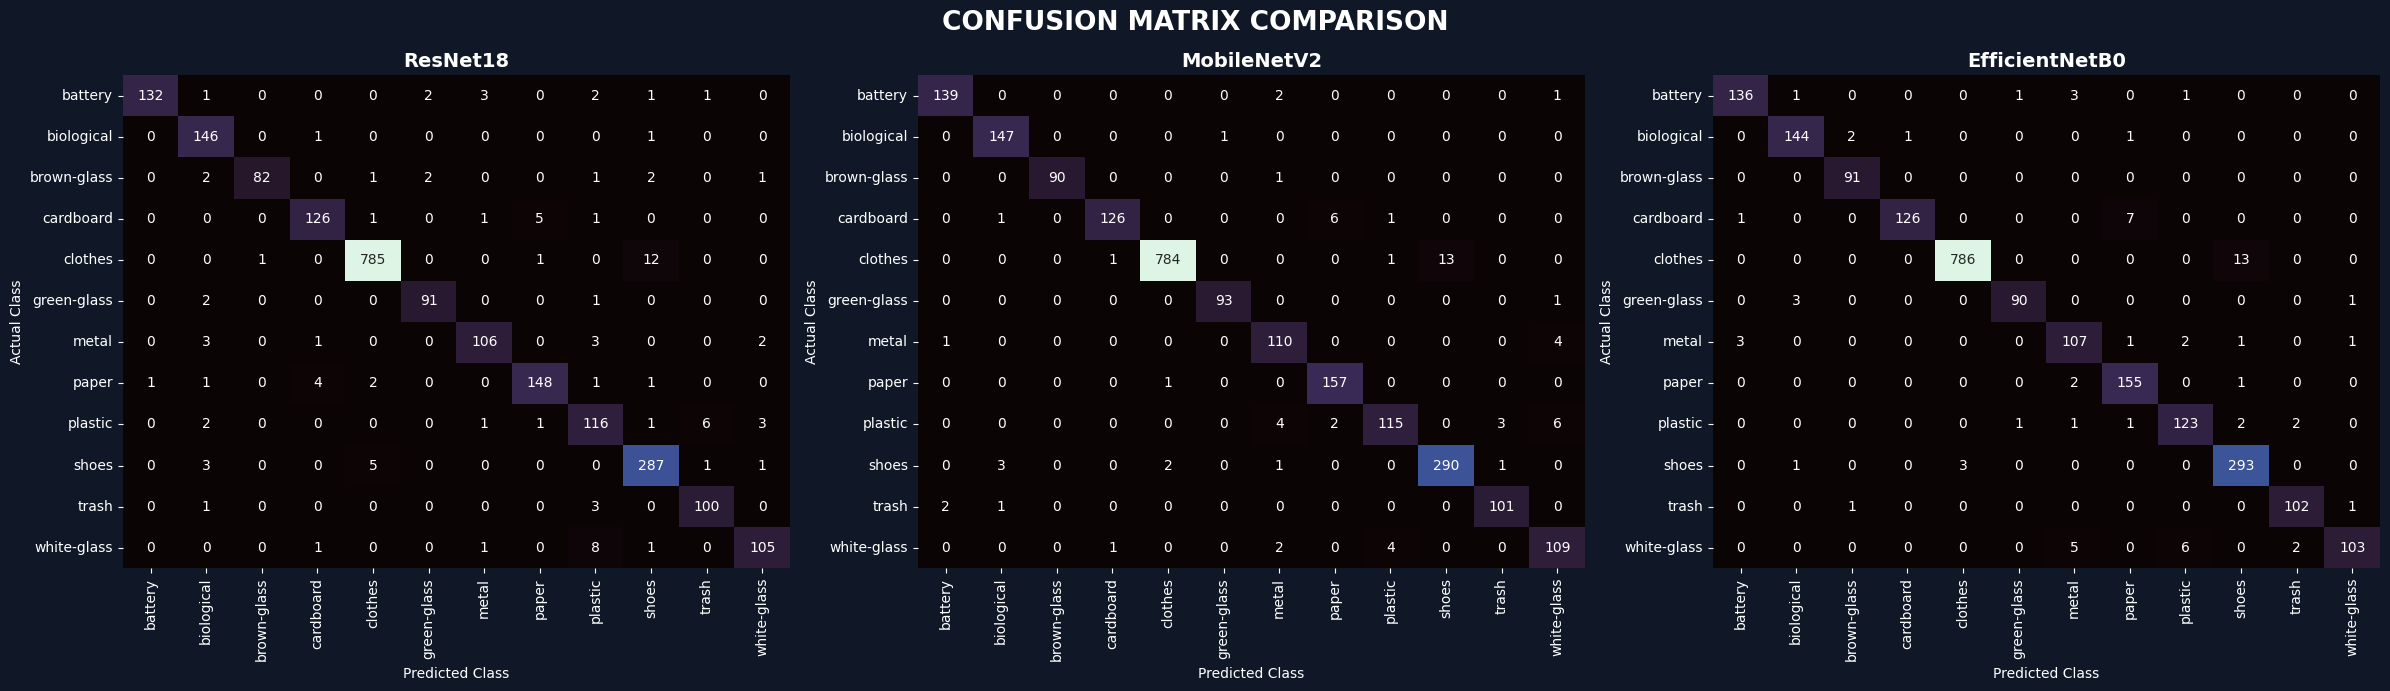

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

fig.patch.set_facecolor("#101827")

for ax, name in zip(axes, model_names):

    cm = confusion_matrix(
        actual_labels[name],
        predictions[name],
        labels=range(num_classes)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="mako",
        xticklabels=full_dataset.classes,
        yticklabels=full_dataset.classes,
        ax=ax,
        cbar=False
    )

    ax.set_title(name, fontsize=14, fontweight="bold", color="white")
    ax.set_xlabel("Predicted Class", color="white")
    ax.set_ylabel("Actual Class", color="white")
    ax.tick_params(axis="x", rotation=90, colors="white")
    ax.tick_params(axis="y", rotation=0, colors="white")

fig.suptitle(
    "CONFUSION MATRIX COMPARISON",
    fontsize=19,
    color="white",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize
import pandas as pd

roc_results = {}

for name in model_names:

    y_true = actual_labels[name]
    y_prob = probabilities[name]

    y_true_binary = label_binarize(
        y_true,
        classes=list(range(num_classes))
    )

    auc_score = roc_auc_score(
        y_true_binary,
        y_prob,
        multi_class="ovr",
        average="macro"
    )

    roc_results[name] = auc_score * 100

    print(name, "ROC-AUC:", round(auc_score * 100, 2), "%")

ResNet18 ROC-AUC: 99.82 %
MobileNetV2 ROC-AUC: 99.93 %
EfficientNetB0 ROC-AUC: 99.95 %


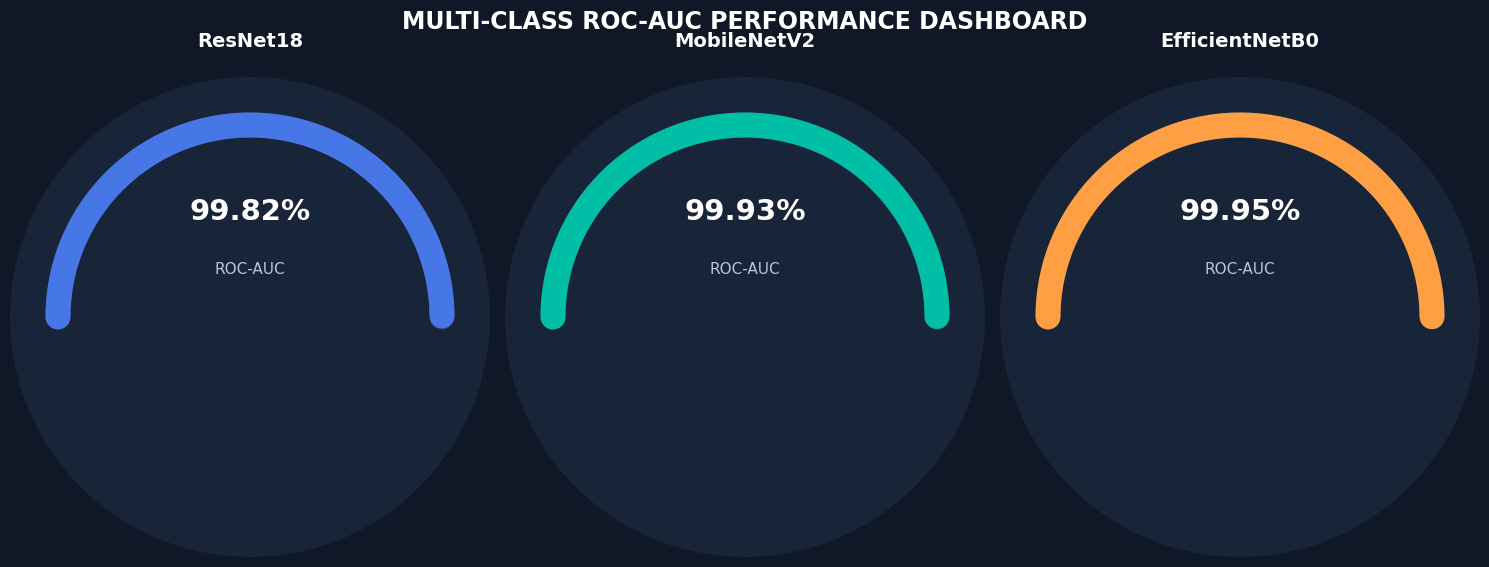

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

names = list(roc_results.keys())
scores = list(roc_results.values())

colors = ["#4776E6", "#00BFA6", "#FF9F43"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 6),
    subplot_kw={"projection": "polar"}
)

fig.patch.set_facecolor("#101827")

for ax, name, score, color in zip(axes, names, scores, colors):

    ax.set_facecolor("#182438")

    # Semicircular gauge background
    theta = np.linspace(np.pi, 0, 200)

    ax.plot(
        theta,
        np.ones_like(theta),
        color="#38465E",
        linewidth=18,
        solid_capstyle="round"
    )

    # Actual ROC-AUC progress
    progress = np.linspace(
        np.pi,
        np.pi - (np.pi * score / 100),
        200
    )

    ax.plot(
        progress,
        np.ones_like(progress),
        color=color,
        linewidth=18,
        solid_capstyle="round"
    )

    # Percentage display
    ax.text(
        np.pi / 2,
        0.55,
        f"{score:.2f}%",
        ha="center",
        va="center",
        fontsize=21,
        fontweight="bold",
        color="white"
    )

    ax.text(
        np.pi / 2,
        0.25,
        "ROC-AUC",
        ha="center",
        va="center",
        fontsize=11,
        color="#B8C4D9"
    )

    ax.set_title(
        name,
        color="white",
        fontsize=14,
        fontweight="bold",
        pad=22
    )

    ax.set_ylim(0, 1.25)
    ax.set_yticks([])
    ax.set_xticks([])
    ax.spines["polar"].set_visible(False)
    ax.grid(False)

fig.suptitle(
    "MULTI-CLASS ROC-AUC PERFORMANCE DASHBOARD",
    fontsize=17,
    fontweight="bold",
    color="white",
    y=0.98
)

plt.tight_layout()
plt.show()

In [ ]:
final_comparison = comparison_df.copy()

final_comparison["ROC-AUC"] = pd.Series(roc_results)
final_comparison["Training Time (min)"] = {
    name: results[name]["training_time"] / 60
    for name in model_names
}

display(final_comparison.round(2))

best_model = final_comparison["Accuracy"].idxmax()

print("\nBEST MODEL:", best_model)
print("TEST ACCURACY:", round(final_comparison.loc[best_model, "Accuracy"], 2), "%")

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (min)
ResNet18,95.53,95.63,95.53,95.54,99.82,5.22
MobileNetV2,97.12,97.17,97.12,97.12,99.93,5.19
EfficientNetB0,96.91,96.96,96.91,96.91,99.95,5.63



BEST MODEL: MobileNetV2
TEST ACCURACY: 97.12 %


In [ ]:
import gradio as gr
import torch
import os
import random

class_names = full_dataset.classes

# ---- Load every trained model that has a saved checkpoint ----
loaded_models = {}
for name in model_names:
    ckpt = f"{name}_best.pth"
    if os.path.exists(ckpt):
        m = create_model(name)
        m.load_state_dict(torch.load(ckpt, map_location=device))
        m.eval()
        loaded_models[name] = m

default_model = best_model if best_model in loaded_models else list(loaded_models)[0]
print("Models available in interface:", list(loaded_models))

# ---- Prediction function ----
def classify_waste(image, model_choice):
    if image is None:
        return None, "⚠️ Please upload or select an image first."

    image = image.convert("RGB")
    tensor = test_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        probs = torch.softmax(loaded_models[model_choice](tensor), dim=1)[0].cpu()

    scores = {class_names[i]: float(probs[i]) for i in range(num_classes)}
    top_prob, top_idx = torch.max(probs, 0)

    summary = (
        f"### ♻️ Predicted: **{class_names[top_idx]}**\n"
        f"Confidence: **{top_prob.item()*100:.2f}%**  |  Model: `{model_choice}`"
    )
    if top_prob.item() < 0.60:
        summary += "\n\n⚠️ Low confidence — try a clearer image with a single item."

    return scores, summary

# ---- Example images from the test split (one per class, up to 6) ----
examples = []
seen = set()
for idx in test_indices:
    path, label = full_dataset.samples[idx]
    if label not in seen:
        seen.add(label)
        examples.append([path, default_model])
    if len(seen) >= 6:
        break

# ---- Interface ----
with gr.Blocks(theme=gr.themes.Soft(), title="Smart Waste Classification") as demo:
    gr.Markdown(
        f"# ♻️ AI-Based Smart Waste Classification\n"
        f"Upload a waste image to classify it into **{num_classes} categories**. "
        f"Best model on test set: **{best_model}**."
    )

    with gr.Row():
        with gr.Column():
            img_input = gr.Image(type="pil", label="Upload Waste Image")
            model_choice = gr.Dropdown(
                choices=list(loaded_models),
                value=default_model,
                label="Select Model",
            )
            with gr.Row():
                clear_btn = gr.Button("Clear")
                submit_btn = gr.Button("Classify", variant="primary")

        with gr.Column():
            summary_out = gr.Markdown()
            label_out = gr.Label(num_top_classes=5, label="Class Probabilities")

    if examples:
        gr.Examples(examples=examples, inputs=[img_input, model_choice], label="Sample test images")

    submit_btn.click(classify_waste, [img_input, model_choice], [label_out, summary_out])
    img_input.change(classify_waste, [img_input, model_choice], [label_out, summary_out])
    model_choice.change(classify_waste, [img_input, model_choice], [label_out, summary_out])
    clear_btn.click(lambda: (None, None, "", None), None,
                    [img_input, label_out, summary_out, model_choice])

demo.launch(share=True, debug=True)

Models available in interface: ['ResNet18', 'MobileNetV2', 'EfficientNetB0']


/tmp/ipykernel_1149/4525024.py:56: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title="Smart Waste Classification") as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://301a2652418932e8bd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://301a2652418932e8bd.gradio.live
